# Setup

In [1]:
from pathlib import Path
from torch_geometric.datasets import MoleculeNet

DATA_ROOT = Path("data/MoleculeNet")

dataset = MoleculeNet(
    root=str(DATA_ROOT),
    name="BBBP"
)

print(dataset)
print("Number of molecules:", len(dataset))
print("First graph:", dataset[0])

BBBP(2039)
Number of molecules: 2039
First graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])


In [2]:
graph = dataset[0]
print("Node-feature shape:", graph.x.shape)
print("Edge-index shape:", graph.edge_index.shape)
print("Edge-feature shape:", graph.edge_attr.shape)
print("Label:", graph.y)
print("SMILES:", graph.smiles)

Node-feature shape: torch.Size([20, 9])
Edge-index shape: torch.Size([2, 40])
Edge-feature shape: torch.Size([40, 3])
Label: tensor([[1.]])
SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


## Imports and global settings

All randomness in this notebook is controlled by one fixed seed (`SEED = 42`).

In [3]:
import random
import textwrap
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import networkx as nx

from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
from torch_geometric.loader import DataLoader
from torch_geometric.utils.smiles import x_map, e_map

RDLogger.DisableLog("rdApp.*")          # silence RDKit parse warnings; invalid SMILES are counted explicitly below
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("torch", torch.__version__)

torch 2.11.0+cu128


# Part A — Define the task and inspect the dataset

## A.1 Task definition

| Item | Description |
|---|---|
| **Input** | One small molecule, given as a SMILES string and converted to a molecular graph (atoms = nodes, chemical bonds = edges, with categorical atom and bond features). |
| **Output** | One probability $P(\text{p\_np}=1 \mid \text{molecule})$ for the whole molecule, turned into a binary decision with a threshold chosen on validation data. |
| **Unit of analysis** | The **molecule** (one graph = one sample = one label). Predictions are graph-level, not per atom. After cleaning, each unique canonical molecule appears exactly once. |
| **Intended technical use** | An educational benchmark for comparing molecular representations (Morgan fingerprints vs. a bond-aware GNN) and evaluation protocols (random vs. scaffold split). At most it could act as an early *in-silico* screening filter for ranking candidates; it is **not** a drug-development or clinical decision tool. |

**Labels (`p_np`)**

* **Positive (1)**: the compound is labelled as *penetrating* the blood–brain barrier (BBB+), i.e. it was reported to reach the central nervous system in meaningful amounts.
* **Negative (0)**: the compound is labelled as *non-penetrating* (BBB−).

These are curated literature labels (Martins et al., 2012) that come from different experimental sources and cut-offs. They are a binarised research annotation, not a clinical measurement for a patient, and say nothing about safety or efficacy.

## A.2 Dataset size, label quality, invalid graphs, class balance

The PyG loader parses each SMILES in the raw CSV with RDKit and **silently skips** molecules that cannot be parsed (the
"Skipping molecule ... zero atoms" warnings above). To report every record I therefore also read the cached raw CSV
(`data/MoleculeNet/bbbp/raw/BBBP.csv`, which PyG downloaded; no separate file is needed) and parse every SMILES myself.

In [4]:
raw_df = pd.read_csv(DATA_ROOT / "bbbp" / "raw" / "BBBP.csv")
raw_df["rdkit_valid"] = [Chem.MolFromSmiles(s) is not None for s in raw_df["smiles"]]

print(f"Raw CSV records                         : {len(raw_df)}")
print(f"Missing SMILES / labels in raw CSV      : {raw_df['smiles'].isna().sum()} / {raw_df['p_np'].isna().sum()}")
print(f"SMILES that RDKit cannot parse (invalid): {(~raw_df['rdkit_valid']).sum()}")
print(f"Graphs kept by the PyG loader           : {len(dataset)}")

invalid_df = raw_df.loc[~raw_df["rdkit_valid"], ["num", "name", "p_np", "smiles"]]
invalid_df

Raw CSV records                         : 2050
Missing SMILES / labels in raw CSV      : 0 / 0
SMILES that RDKit cannot parse (invalid): 11
Graphs kept by the PyG loader           : 2039


,num,name,p_np,smiles
59,60,15,1,O=N([O-])C1=C(CN=C1NCCSCc2ncccc2)Cc3ccccc3
61,62,22767,1,c1(nc(NC(N)=[NH2])sc1)CSCCNC(=[NH]C#N)NC
391,393,ICI17148,1,Cc1nc(sc1)\[NH]=C(\N)N
614,616,5-6,1,s1cc(CSCCN\C(NC)=[NH]\C#N)nc1\[NH]=C(\N)N
642,644,12,0,c1c(c(ncc1)CSCCN\C(=[NH]\C#N)NCC)Br
645,647,16,1,n1c(csc1\[NH]=C(\N)N)c1ccccc1
646,648,17,0,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)N
647,649,18,0,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)NC(C)=O
648,650,19,0,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)N\C(NC)=[NH]\C#N
649,651,2,1,s1cc(nc1\[NH]=C(\N)N)C


In [5]:
# One row per PyG graph (the PyG dataset keeps CSV order, skipping the invalid rows)
records = []
for i, g in enumerate(dataset):
    y = g.y.view(-1)
    records.append({
        "idx": i,
        "smiles": g.smiles,
        "y": float(y[0]) if y.numel() == 1 else np.nan,
        "n_atoms": int(g.num_nodes),
        "n_bonds": int(g.edge_index.size(1) // 2),   # each chemical bond is stored as two directed edges
    })
mol_df = pd.DataFrame(records)

# Sanity: the PyG graphs are exactly the RDKit-valid raw rows, in the same order
assert mol_df["smiles"].tolist() == raw_df.loc[raw_df["rdkit_valid"], "smiles"].tolist()
mol_df["name"] = raw_df.loc[raw_df["rdkit_valid"], "name"].values

n_nonfinite = (~np.isfinite(mol_df["y"])).sum()
n_empty     = (mol_df["n_atoms"] == 0).sum()
n_no_edges  = (mol_df["n_bonds"] == 0).sum()

# Canonicalize every valid SMILES with RDKit (stereochemistry is kept)
mol_df["canonical"] = [Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in mol_df["smiles"]]
n_bad_canon = mol_df["canonical"].isin(["", None]).sum()

print(f"Graphs in PyG dataset              : {len(mol_df)}")
print(f"Missing / non-finite labels        : {n_nonfinite}")
print(f"Empty graphs (0 atoms)             : {n_empty}")
print(f"Graphs with atoms but no bonds     : {n_no_edges}   (isolated counter-ion nodes such as [Cl] can still occur inside a graph)")
print(f"Failed canonicalizations           : {n_bad_canon}")
print(f"Records with multiple fragments '.': {mol_df['smiles'].str.contains('.', regex=False).sum()}  (salts / counter-ions, kept as one record)")

def class_table(y):
    c = pd.Series(y).astype(int).value_counts().sort_index()
    return pd.DataFrame({"count": c, "proportion": (c / c.sum()).round(4)}).rename(index={0: "0 (BBB-)", 1: "1 (BBB+)"})

print("\nClass balance (raw CSV, all 2050 rows):")
display(class_table(raw_df["p_np"]))
print("Class balance (PyG graphs, before de-duplication):")
display(class_table(mol_df["y"]))

Graphs in PyG dataset              : 2039
Missing / non-finite labels        : 0
Empty graphs (0 atoms)             : 0
Graphs with atoms but no bonds     : 0   (isolated counter-ion nodes such as [Cl] can still occur inside a graph)
Failed canonicalizations           : 0
Records with multiple fragments '.': 105  (salts / counter-ions, kept as one record)

Class balance (raw CSV, all 2050 rows):


,count,proportion
p_np,,
0 (BBB-),483,0.2356
1 (BBB+),1567,0.7644


Class balance (PyG graphs, before de-duplication):


,count,proportion
y,,
0 (BBB-),479,0.2349
1 (BBB+),1560,0.7651


### Duplicate molecules

Duplicates are detected on the **RDKit canonical SMILES**, so the same molecule written in two different ways
(e.g. `CC(=O)Oc1ccccc1C(O)=O` and `C1=CC=CC(=C1C(O)=O)OC(C)=O`, both aspirin) is caught even when the raw strings differ.

In [6]:
grp = mol_df.groupby("canonical")["y"].agg(n_records="size", n_labels="nunique")
dup_groups      = grp[grp["n_records"] > 1]
conflict_groups = grp[grp["n_labels"] > 1]
consistent_dups = dup_groups[dup_groups["n_labels"] == 1]

exact_raw_dups = mol_df["smiles"].duplicated(keep=False).sum()
print(f"Unique canonical molecules                       : {len(grp)}")
print(f"Canonical molecules occurring more than once     : {len(dup_groups)}  ({dup_groups['n_records'].sum()} records)")
print(f"   ...of which raw SMILES strings are identical  : {exact_raw_dups} records -> all duplicates use different SMILES strings")
print(f"   ...with consistent labels                     : {len(consistent_dups)} groups ({consistent_dups['n_records'].sum()} records)")
print(f"   ...with CONFLICTING labels                    : {len(conflict_groups)} groups ({conflict_groups['n_records'].sum()} records)")
print(f"Group size distribution                          : {dict(Counter(dup_groups['n_records']))}")

print("\nExamples of consistent duplicates (different raw SMILES, same canonical molecule):")
display(mol_df[mol_df["canonical"].isin(consistent_dups.index[:3])]
        .sort_values("canonical")[["idx", "name", "y", "smiles", "canonical"]])

Unique canonical molecules                       : 1975
Canonical molecules occurring more than once     : 60  (124 records)
   ...of which raw SMILES strings are identical  : 0 records -> all duplicates use different SMILES strings
   ...with consistent labels                     : 50 groups (104 records)
   ...with CONFLICTING labels                    : 10 groups (20 records)
Group size distribution                          : {2: 56, 3: 4}

Examples of consistent duplicates (different raw SMILES, same canonical molecule):


,idx,name,y,smiles,canonical
432,432,Divinylether,1.0,C=COC=C,C=COC=C
1647,1647,vinyl-ether,1.0,C(=C)OC=C,C=COC=C
3,3,24,1.0,C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C,CC(=O)NCCCOc1cccc(CN2CCCCC2)c1
655,655,24,1.0,C1CN(CCC1)Cc1cccc(c1)OCCCNC(=O)C,CC(=O)NCCCOc1cccc(CN2CCCCC2)c1
97,97,acetaminophen,1.0,CC(=O)Nc1ccc(O)cc1,CC(=O)Nc1ccc(O)cc1
1932,1932,paracetamol(acetaminophen),1.0,N(C(=O)C)C1=CC=C(O)C=C1,CC(=O)Nc1ccc(O)cc1


In [7]:
print("Records in conflicting-label groups (all will be removed):")
conflict_df = (mol_df[mol_df["canonical"].isin(conflict_groups.index)]
               .sort_values(["canonical", "y"])[["idx", "name", "y", "smiles", "canonical"]])
conflict_df

Records in conflicting-label groups (all will be removed):


,idx,name,y,smiles,canonical
98,98,acetylsalicylate,0.0,CC(=O)Oc1ccccc1C(O)=O,CC(=O)Oc1ccccc1C(=O)O
996,996,aspirin,1.0,C1=CC=CC(=C1C(O)=O)OC(C)=O,CC(=O)Oc1ccccc1C(=O)O
566,566,loratadine,0.0,CCOC(=O)N1CCC(CC1)=C2c3ccc(Cl)cc3CCc4cccnc24,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1
1323,1323,loratadine,1.0,C1=CC(=CC2=C1C(C3=C(CC2)C=CC=N3)=C4CCN(C(OCC)=O)CC4)Cl,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1
547,547,loperamide,0.0,CN(C)C(=O)C(CCN1CCC(O)(CC1)c2ccc(Cl)cc2)(c3ccccc3)c4ccccc4,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1
16,16,BRL53080,1.0,CN(C)C(=O)C(CCN1CCC(O)(CC1)c1ccc(Cl)cc1)(c1ccccc1)c1ccccc1,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1
124,124,atropine,0.0,CN1C2CCC1CC(C2)OC(=O)C(CO)c3ccccc3,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
1686,1686,atropine(hyoscyamine),1.0,C1=CC=CC=C1C(C(OC2CC3N(C)C(C2)CC3)=O)CO,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
172,172,Trimetrexate,0.0,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC
1630,1630,trimetrexate,1.0,C1=C3C(=C(C(=C1)CNC2=CC(=C(C(=C2)OC)OC)OC)C)C(=NC(=N3)N)N,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC


### Cleaning rule (applied once, before any split)

1. Remove invalid SMILES / empty graphs (11 raw rows that RDKit cannot parse; PyG already dropped them, and there are no empty graphs left).
2. Remove **all** records of a canonical molecule whose duplicate records have **conflicting** labels.
3. For duplicate groups with **consistent** labels, keep the **first** record (lowest index) and drop the rest.

Both split strategies in Part C are built from the resulting `clean_df` / `clean_graphs`.

In [8]:
n_raw = len(raw_df)
step1 = mol_df[(mol_df["n_atoms"] > 0) & np.isfinite(mol_df["y"])]
step2 = step1[~step1["canonical"].isin(conflict_groups.index)]
step3 = step2.drop_duplicates(subset="canonical", keep="first")
clean_df = step3.reset_index(drop=True)

cleaning_log = pd.DataFrame([
    ("Raw CSV records",                                       n_raw,                    ""),
    ("Removed: invalid SMILES (RDKit parse failure)",        n_raw - len(mol_df),       "dropped by PyG loader"),
    ("Removed: empty graph / non-finite label",              len(mol_df) - len(step1),  ""),
    ("Removed: records in conflicting-label groups",         len(step1) - len(step2),   f"{len(conflict_groups)} molecules"),
    ("Removed: redundant copies of consistent duplicates",   len(step2) - len(step3),   f"{len(consistent_dups)} molecules kept once"),
    ("Clean molecules used for all splits",                  len(clean_df),             ""),
], columns=["step", "records", "note"])
display(cleaning_log)

assert clean_df["canonical"].is_unique
print("Class balance after cleaning:")
display(class_table(clean_df["y"]))

,step,records,note
0,Raw CSV records,2050,
1,Removed: invalid SMILES (RDKit parse failure),11,dropped by PyG loader
2,Removed: empty graph / non-finite label,0,
3,Removed: records in conflicting-label groups,20,10 molecules
4,Removed: redundant copies of consistent duplicates,54,50 molecules kept once
5,Clean molecules used for all splits,1965,


Class balance after cleaning:


,count,proportion
y,,
0 (BBB-),465,0.2366
1 (BBB+),1500,0.7634


The dataset is **imbalanced**: roughly three quarters of the molecules are BBB+. Accuracy alone is therefore
misleading (predicting "1" for everything gives ~76 % accuracy), so later parts report ROC-AUC, PR-AUC, sensitivity,
specificity and F1 as well.

## A.3 Example molecular structures (both classes)

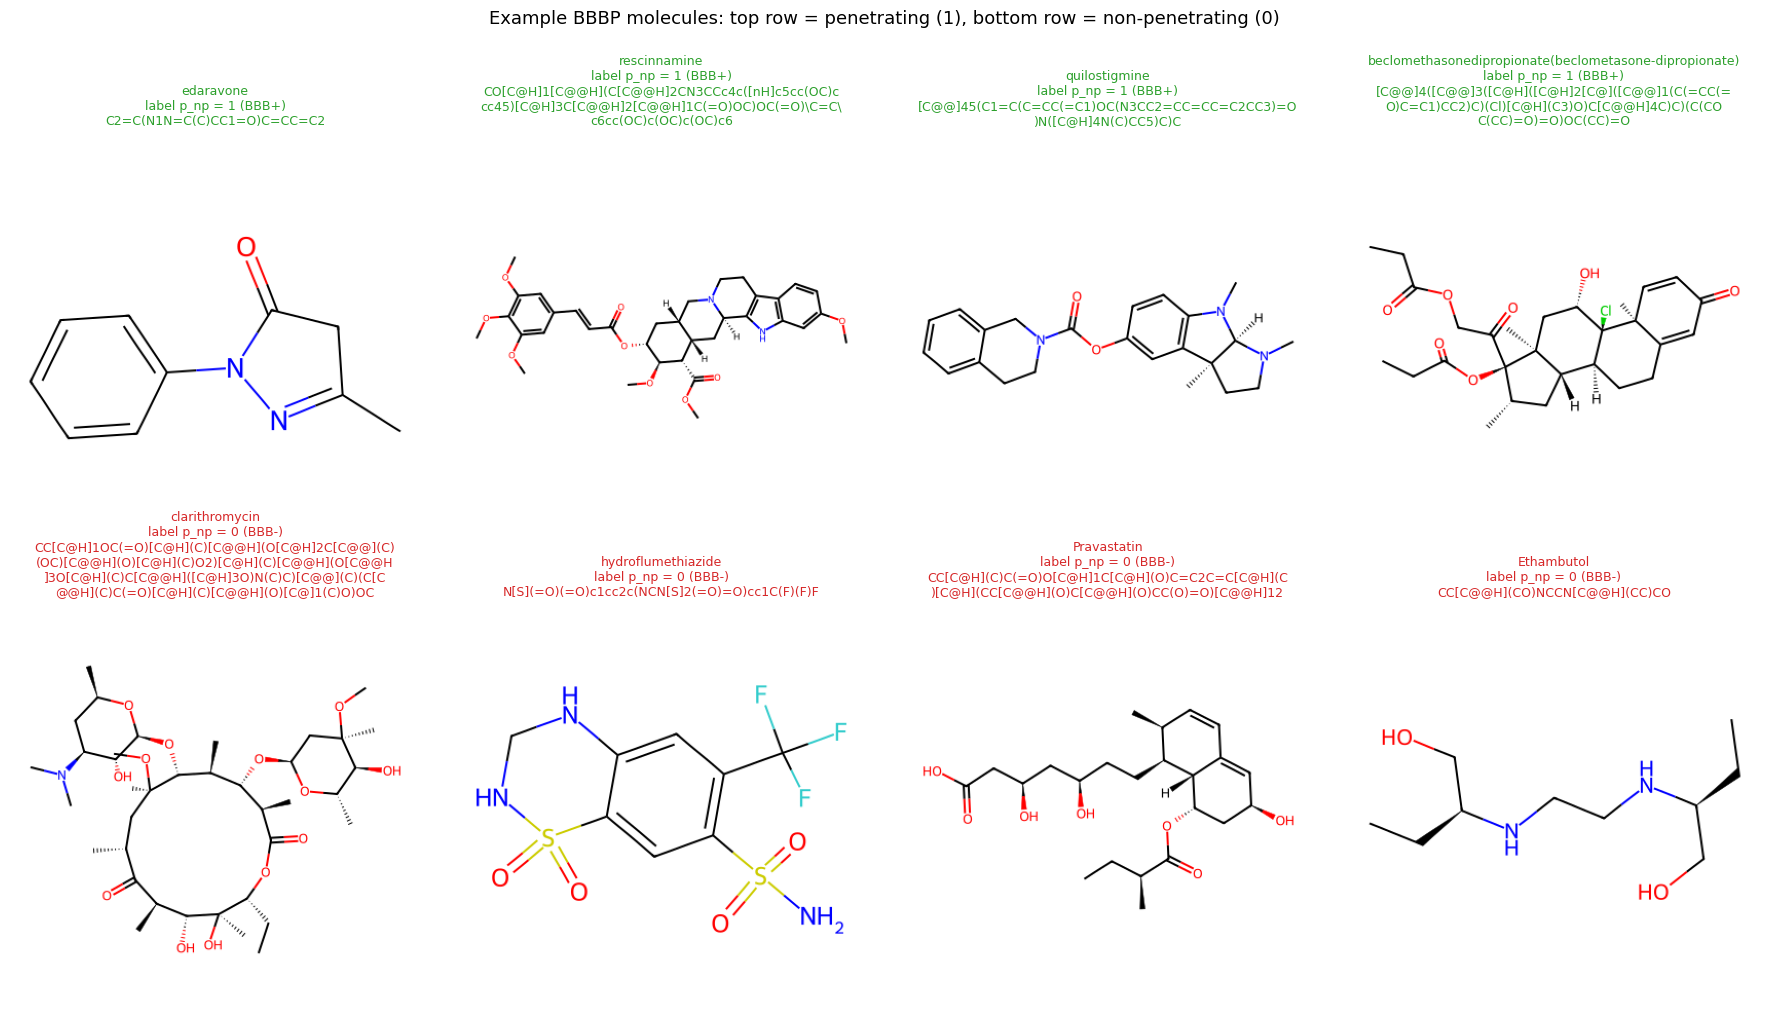

,name,y,smiles
1123,edaravone,1.0,C2=C(N1N=C(C)CC1=O)C=CC=C2
187,rescinnamine,1.0,CO[C@H]1[C@@H](C[C@@H]2CN3CCc4c([nH]c5cc(OC)ccc45)[C@H]3C[C@@H]2[C@@H]1C(=O)OC)OC(=O)\...
1446,quilostigmine,1.0,[C@@]45(C1=C(C=CC(=C1)OC(N3CC2=CC=CC=C2CC3)=O)N([C@H]4N(C)CC5)C)C
1624,beclomethasonedipropionate(beclometasone-dipropionate),1.0,[C@@]4([C@@]3([C@H]([C@H]2[C@]([C@@]1(C(=CC(=O)C=C1)CC2)C)(Cl)[C@H](C3)O)C[C@@H]4C)C)(...
750,clarithromycin,0.0,CC[C@H]1OC(=O)[C@H](C)[C@@H](O[C@H]2C[C@@](C)(OC)[C@@H](O)[C@H](C)O2)[C@H](C)[C@@H](O[...
257,hydroflumethiazide,0.0,N[S](=O)(=O)c1cc2c(NCN[S]2(=O)=O)cc1C(F)(F)F
166,Pravastatin,0.0,CC[C@H](C)C(=O)O[C@H]1C[C@H](O)C=C2C=C[C@H](C)[C@H](CC[C@@H](O)C[C@@H](O)CC(O)=O)[C@@H]12
672,Ethambutol,0.0,CC[C@@H](CO)NCCN[C@@H](CC)CO


In [9]:
rng = np.random.default_rng(SEED)
show_idx = np.concatenate([
    rng.choice(clean_df.index[clean_df["y"] == 1], 4, replace=False),
    rng.choice(clean_df.index[clean_df["y"] == 0], 4, replace=False),
])

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, i in zip(axes.ravel(), show_idx):
    row = clean_df.loc[i]
    mol = Chem.MolFromSmiles(row["smiles"])
    ax.imshow(Draw.MolToImage(mol, size=(400, 400)))
    ax.axis("off")
    label = int(row["y"])
    ax.set_title(f"{row['name']}\nlabel p_np = {label} ({'BBB+' if label else 'BBB-'})\n"
                 + "\n".join(textwrap.wrap(row["smiles"], 45)),
                 fontsize=9, color="tab:green" if label else "tab:red")
fig.suptitle("Example BBBP molecules: top row = penetrating (1), bottom row = non-penetrating (0)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

clean_df.loc[show_idx, ["name", "y", "smiles"]]

## A.4 Atom-count and bond-count distributions

Atom count = number of graph nodes (heavy atoms; hydrogens are implicit and stored as the `num_hs` feature).
Bond count = number of chemical bonds = `edge_index.shape[1] / 2`, because each bond is stored as two directed edges.

y              BBB- (0)  BBB+ (1)
n_atoms count    465.00   1500.00
        mean      30.51     22.28
        std       15.06      7.93
        min        8.00      2.00
        25%       22.00     17.00
        50%       28.00     22.00
        75%       35.00     27.00
        max      132.00     76.00
n_bonds count    465.00   1500.00
        mean      32.67     24.10
        std       16.31      9.08
        min        6.00      1.00
        25%       24.00     18.00
        50%       30.00     24.00
        75%       37.00     30.00
        max      145.00     83.00

,count,mean,std,min,25%,50%,75%,max
n_atoms,1965.0,24.22,10.67,2.0,18.0,23.0,29.0,132.0
n_bonds,1965.0,26.13,11.79,1.0,19.0,25.0,31.0,145.0


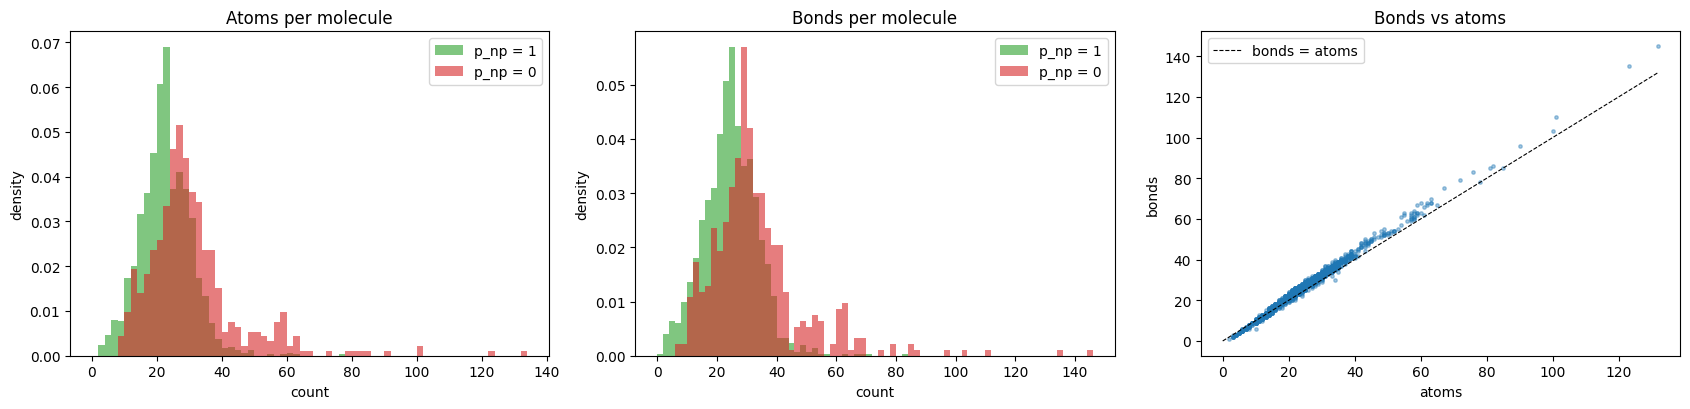

In [10]:
display(clean_df.groupby("y")[["n_atoms", "n_bonds"]].describe().T.round(2)
        .rename(columns={0.0: "BBB- (0)", 1.0: "BBB+ (1)"}))
display(clean_df[["n_atoms", "n_bonds"]].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, title in [(axes[0], "n_atoms", "Atoms per molecule"), (axes[1], "n_bonds", "Bonds per molecule")]:
    bins = np.arange(0, clean_df[col].max() + 3, 2)
    for lab, colr in [(1, "tab:green"), (0, "tab:red")]:
        ax.hist(clean_df.loc[clean_df["y"] == lab, col], bins=bins, alpha=0.6, color=colr,
                label=f"p_np = {lab}", density=True)
    ax.set_title(title); ax.set_xlabel("count"); ax.set_ylabel("density"); ax.legend()
axes[2].scatter(clean_df["n_atoms"], clean_df["n_bonds"], s=6, alpha=0.4)
axes[2].plot([0, clean_df["n_atoms"].max()], [0, clean_df["n_atoms"].max()], "k--", lw=0.8, label="bonds = atoms")
axes[2].set_xlabel("atoms"); axes[2].set_ylabel("bonds"); axes[2].set_title("Bonds vs atoms"); axes[2].legend()
plt.tight_layout(); plt.show()

Most molecules are drug-sized (median 23 heavy atoms, long right tail up to >100 atoms for large peptides/macrolides).
Bond count tracks atom count almost linearly (bonds ≈ atoms − 1 + number of rings). BBB− molecules tend to be larger,
which is consistent with the known preference of BBB-penetrating drugs for low molecular weight.

### Inspecting one graph

In [11]:
graph = dataset[0]
print("x.shape          :", tuple(graph.x.shape), "  -> 20 atoms x 9 categorical atom features")
print("edge_index.shape :", tuple(graph.edge_index.shape), "  -> 2 x 40 directed edges = 20 bonds")
print("edge_attr.shape  :", tuple(graph.edge_attr.shape), "  -> 40 directed edges x 3 categorical bond features")
print("y                :", graph.y, " shape", tuple(graph.y.shape), " -> one graph-level label (BBB+)")
print("smiles           :", graph.smiles)
print("\nx (first 5 atoms):\n", graph.x[:5])
print("edge_index (first 8 edges):\n", graph.edge_index[:, :8])

x.shape          : (20, 9)   -> 20 atoms x 9 categorical atom features
edge_index.shape : (2, 40)   -> 2 x 40 directed edges = 20 bonds
edge_attr.shape  : (40, 3)   -> 40 directed edges x 3 categorical bond features
y                : tensor([[1.]])  shape (1, 1)  -> one graph-level label (BBB+)
smiles           : [Cl].CC(C)NCC(O)COc1cccc2ccccc12

x (first 5 atoms):
 tensor([[17,  0,  0,  5,  0,  1,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
        [ 6,  0,  4,  5,  1,  0,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
        [ 7,  0,  3,  5,  1,  0,  4,  0,  0]])
edge_index (first 8 edges):
 tensor([[1, 2, 2, 2, 3, 4, 4, 5],
        [2, 1, 3, 4, 2, 2, 5, 4]])


Note: Propranolol hydrochloride is written as `[Cl].CC(C)NCC(O)...`, so the graph contains a disconnected
chloride node with no edges. That gives 20 nodes (19 heavy atoms of propranolol + 1 Cl). Propranolol is one connected
component with 2 rings (naphthalene), so it has 19 − 1 + 2 = 20 bonds → 40 directed edges. This is also why the
first edge in `edge_index` starts at node 1: node 0 is the isolated chloride.

# Part B — Construct and batch molecular graphs

## B.1 Graph representation and feature encoding

In PyG's `from_smiles` each molecule becomes a `Data` object:

* **Nodes = heavy atoms** (in RDKit atom order). Hydrogens are implicit, stored as a node feature.
* **Edges = chemical bonds.** Each undirected bond *i–j* is stored twice (*i→j* and *j→i*) in `edge_index` (shape `[2, 2·n_bonds]`)
  so messages can flow both ways. `edge_attr[k]` describes the bond of edge *k*.
* `x` (shape `[n_atoms, 9]`) and `edge_attr` (shape `[2·n_bonds, 3]`) contain **integer category codes**: each value is an
  *index into a vocabulary list* (`torch_geometric.utils.smiles.x_map` / `e_map`), not the physical value itself.
  For example formal charge 0 is stored as code 5, because the vocabulary is `[-5, …, 6]`.

In [12]:
atom_desc = {
    "atomic_num": "element (atomic number Z), e.g. code 6 = carbon",
    "chirality": "tetrahedral chirality tag (R/S information in CW/CCW form)",
    "degree": "total number of bonded neighbours including implicit H",
    "formal_charge": "formal charge of the atom",
    "num_hs": "total number of attached hydrogens",
    "num_radical_electrons": "number of unpaired electrons",
    "hybridization": "orbital hybridization (SP, SP2, SP3, ...)",
    "is_aromatic": "atom is part of an aromatic system",
    "is_in_ring": "atom is part of any ring",
}
bond_desc = {
    "bond_type": "bond order: SINGLE, DOUBLE, TRIPLE, AROMATIC, ...",
    "stereo": "double-bond stereochemistry (E/Z, cis/trans, none)",
    "is_conjugated": "bond is part of a conjugated system",
}
all_x  = torch.cat([g.x for g in dataset])
all_ea = torch.cat([g.edge_attr for g in dataset if g.edge_attr.numel()])

def feature_table(fmap, desc, data):
    rows = []
    for col, (name, vocab) in enumerate(fmap.items()):
        used = sorted(data[:, col].unique().tolist())
        rows.append({"column": col, "feature": name, "meaning": desc[name],
                     "vocab_size": len(vocab), "categories seen in BBBP": [vocab[u] for u in used]})
    return pd.DataFrame(rows)

print("Atom (node) features, graph.x columns:")
display(feature_table(x_map, atom_desc, all_x))
print("Bond (edge) features, graph.edge_attr columns:")
display(feature_table(e_map, bond_desc, all_ea))

Atom (node) features, graph.x columns:


,column,feature,meaning,vocab_size,categories seen in BBBP
0,0,atomic_num,"element (atomic number Z), e.g. code 6 = carbon",119,"[1, 5, 6, 7, 8, 9, 11, 15, 16, 17, 20, 35, 53]"
1,1,chirality,tetrahedral chirality tag (R/S information in CW/CCW form),9,"[CHI_UNSPECIFIED, CHI_TETRAHEDRAL_CW, CHI_TETRAHEDRAL_CCW]"
2,2,degree,total number of bonded neighbours including implicit H,11,"[0, 1, 2, 3, 4]"
3,3,formal_charge,formal charge of the atom,12,"[-1, 0, 1, 2]"
4,4,num_hs,total number of attached hydrogens,9,"[0, 1, 2, 3]"
5,5,num_radical_electrons,number of unpaired electrons,5,"[0, 1]"
6,6,hybridization,"orbital hybridization (SP, SP2, SP3, ...)",8,"[S, SP, SP2, SP3]"
7,7,is_aromatic,atom is part of an aromatic system,2,"[False, True]"
8,8,is_in_ring,atom is part of any ring,2,"[False, True]"


Bond (edge) features, graph.edge_attr columns:


,column,feature,meaning,vocab_size,categories seen in BBBP
0,0,bond_type,"bond order: SINGLE, DOUBLE, TRIPLE, AROMATIC, ...",22,"[SINGLE, DOUBLE, TRIPLE, AROMATIC]"
1,1,stereo,"double-bond stereochemistry (E/Z, cis/trans, none)",6,"[STEREONONE, STEREOZ, STEREOE]"
2,2,is_conjugated,bond is part of a conjugated system,2,"[False, True]"


**Encoding choice: one-hot encoding.** Every categorical column is replaced by a one-hot block whose length equals the
full PyG vocabulary size, and the blocks are concatenated:

* atoms: 119 + 9 + 11 + 12 + 9 + 5 + 8 + 2 + 2 = **177-dimensional** binary node vector
* bonds: 22 + 6 + 2 = **30-dimensional** binary edge vector

So no ordering or distance between codes is implied (carbon = 6 is not "half of" sulfur = 16), which is what would
happen if the raw integer codes were fed as continuous numbers. Using the fixed full vocabulary (not only the categories
seen in the data) keeps the encoding identical for every split and for any unseen molecule. The GNN's first linear layer
on top of these one-hot vectors is equivalent to a trainable embedding per category, summed over columns.

The raw codes are kept as `x_cat` / `edge_attr_cat` for plotting and inspection only.

In [13]:
ATOM_VOCAB = [len(v) for v in x_map.values()]
BOND_VOCAB = [len(v) for v in e_map.values()]
ATOM_DIM, BOND_DIM = sum(ATOM_VOCAB), sum(BOND_VOCAB)

def one_hot_columns(codes: torch.Tensor, vocab_sizes) -> torch.Tensor:
    """codes: [N, C] long tensor of category indices -> [N, sum(vocab_sizes)] float one-hot."""
    if codes.numel() == 0:
        return torch.zeros((codes.size(0), sum(vocab_sizes)), dtype=torch.float)
    blocks = [torch.nn.functional.one_hot(codes[:, c], num_classes=k) for c, k in enumerate(vocab_sizes)]
    return torch.cat(blocks, dim=1).float()

def encode_graph(g, canonical, name):
    d = g.clone()
    d.x_cat, d.edge_attr_cat = g.x, g.edge_attr.view(-1, len(BOND_VOCAB))
    d.x = one_hot_columns(g.x, ATOM_VOCAB)
    d.edge_attr = one_hot_columns(d.edge_attr_cat, BOND_VOCAB)
    d.y = g.y.view(1, 1).float()          # one label per graph -> batch.y has shape [num_graphs, 1]
    d.canonical = canonical
    d.name = name
    return d

clean_graphs = [encode_graph(dataset[int(r.idx)], r.canonical, r.name) for r in clean_df.itertuples()]
g0 = clean_graphs[0]
print(f"Cleaned & encoded graphs: {len(clean_graphs)}")
print(f"Atom one-hot dim = {ATOM_DIM}, bond one-hot dim = {BOND_DIM}")
print(g0)
# each atom row must contain exactly one '1' per categorical column
assert torch.all(g0.x.sum(1) == len(ATOM_VOCAB)) and torch.all(g0.edge_attr.sum(1) == len(BOND_VOCAB))
print("Row sums of one-hot x (should all equal 9):", g0.x.sum(1)[:10].tolist())

Cleaned & encoded graphs: 1965
Atom one-hot dim = 177, bond one-hot dim = 30
Data(x=[20, 177], edge_index=[2, 40], edge_attr=[40, 30], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1], x_cat=[20, 9], edge_attr_cat=[40, 3], canonical='CC(C)NCC(O)COc1cccc2ccccc12.[Cl]', name='Propanolol')
Row sums of one-hot x (should all equal 9): [9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0]


## B.2 The same molecule as a chemical structure and as a node–edge graph

I use **paracetamol** (acetaminophen, `CC(=O)Nc1ccc(O)cc1`, BBB+): it is small enough to read and still contains
an aromatic ring, a C=O double bond and heteroatoms.

Name: acetaminophen | label: 1 | SMILES: CC(=O)Nc1ccc(O)cc1
x.shape (11, 177) | edge_index.shape (2, 22) | edge_attr.shape (22, 30)


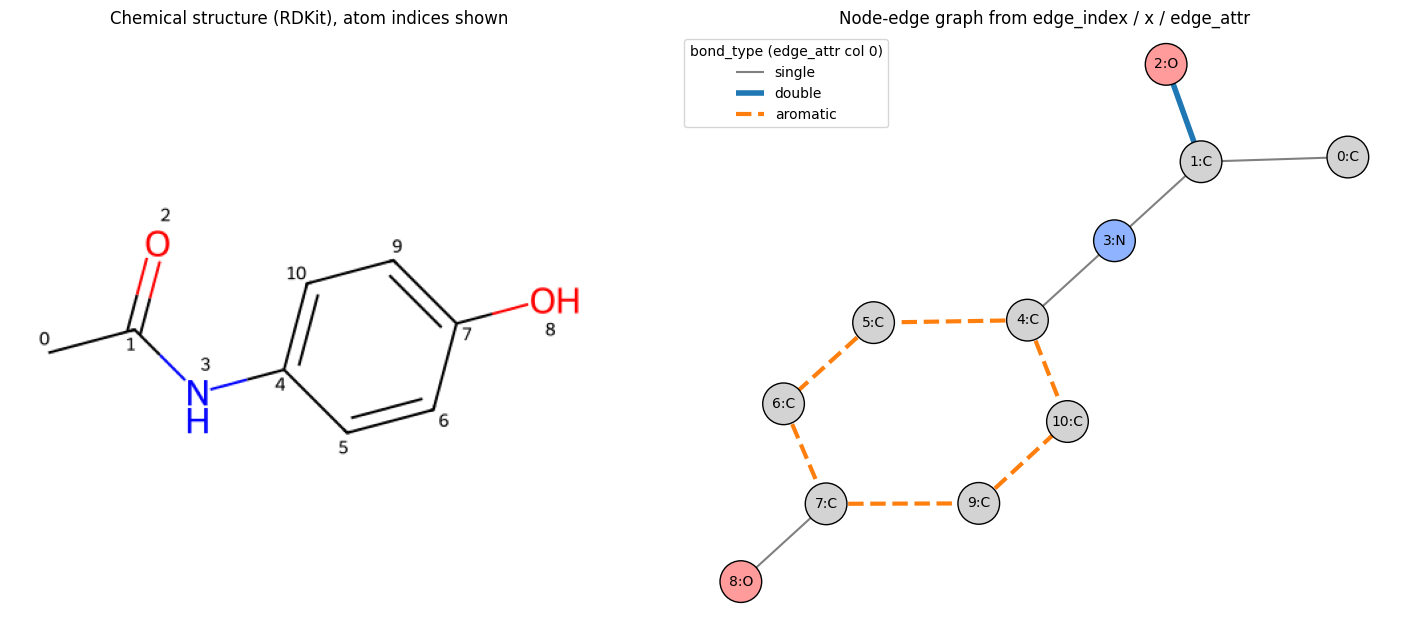

Node table (decoded x_cat, one row per node):


,symbol,atomic_num,degree,num_hs,hybridization,is_aromatic,is_in_ring,formal_charge
0,C,6,4,3,SP3,False,False,0
1,C,6,3,0,SP2,False,False,0
2,O,8,1,0,SP2,False,False,0
3,N,7,3,1,SP2,False,False,0
4,C,6,3,0,SP2,True,True,0
5,C,6,3,1,SP2,True,True,0
6,C,6,3,1,SP2,True,True,0
7,C,6,3,0,SP2,True,True,0
8,O,8,2,1,SP2,False,False,0
9,C,6,3,1,SP2,True,True,0


Edge table (both directions of every bond):


,edge k,src,dst,bond_type,stereo,is_conjugated
0,0,0:C,1:C,SINGLE,STEREONONE,False
1,1,1:C,0:C,SINGLE,STEREONONE,False
2,2,1:C,2:O,DOUBLE,STEREONONE,True
3,3,1:C,3:N,SINGLE,STEREONONE,True
4,4,2:O,1:C,DOUBLE,STEREONONE,True
5,5,3:N,1:C,SINGLE,STEREONONE,True
6,6,3:N,4:C,SINGLE,STEREONONE,True
7,7,4:C,3:N,SINGLE,STEREONONE,True


In [14]:
ex_pos = int(np.flatnonzero(clean_df["canonical"] == Chem.MolToSmiles(Chem.MolFromSmiles("CC(=O)Nc1ccc(O)cc1")))[0])
ex = clean_graphs[ex_pos]
mol = Chem.MolFromSmiles(ex.smiles)          # same parsing as PyG -> same atom order / indices
print("Name:", ex.name, "| label:", int(ex.y.item()), "| SMILES:", ex.smiles)
print("x.shape", tuple(ex.x.shape), "| edge_index.shape", tuple(ex.edge_index.shape), "| edge_attr.shape", tuple(ex.edge_attr.shape))

# --- left: conventional chemical structure with RDKit atom indices
d_opts_mol = Chem.Mol(mol)
for a in d_opts_mol.GetAtoms():
    a.SetProp("atomNote", str(a.GetIdx()))
struct_img = Draw.MolToImage(d_opts_mol, size=(450, 450))

# --- right: node-edge graph built ONLY from the PyG tensors
sym = [Chem.GetPeriodicTable().GetElementSymbol(x_map["atomic_num"][int(c)]) for c in ex.x_cat[:, 0]]
bond_names = e_map["bond_type"]
G = nx.Graph()
for i in range(ex.num_nodes):
    G.add_node(i, label=f"{i}:{sym[i]}")
for k in range(ex.edge_index.size(1)):
    i, j = ex.edge_index[:, k].tolist()
    if i < j:                                # draw each undirected bond once
        G.add_edge(i, j, btype=bond_names[int(ex.edge_attr_cat[k, 0])])

style = {"SINGLE": ("grey", 1.5, "solid"), "DOUBLE": ("tab:blue", 4, "solid"), "AROMATIC": ("tab:orange", 3, "dashed")}
pos = nx.kamada_kawai_layout(G)
elem_color = {"C": "lightgrey", "N": "#8fb3ff", "O": "#ff9b9b"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
axes[0].imshow(struct_img); axes[0].axis("off"); axes[0].set_title("Chemical structure (RDKit), atom indices shown")
for bt, (c, w, ls) in style.items():
    es = [(u, v) for u, v, d in G.edges(data=True) if d["btype"] == bt]
    nx.draw_networkx_edges(G, pos, edgelist=es, edge_color=c, width=w, style=ls, ax=axes[1], label=bt.lower())
nx.draw_networkx_nodes(G, pos, node_color=[elem_color.get(s, "khaki") for s in sym], node_size=900, edgecolors="k", ax=axes[1])
nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "label"), font_size=10, ax=axes[1])
axes[1].legend(title="bond_type (edge_attr col 0)", loc="upper left")
axes[1].set_title("Node-edge graph from edge_index / x / edge_attr"); axes[1].axis("off")
plt.tight_layout(); plt.show()

atom_tbl = pd.DataFrame(ex.x_cat.numpy(), columns=list(x_map.keys()))
atom_tbl.insert(0, "symbol", sym)
for col, vocab in x_map.items():                         # decode codes -> human-readable categories
    atom_tbl[col] = [vocab[int(c)] for c in atom_tbl[col]]
print("Node table (decoded x_cat, one row per node):")
display(atom_tbl[["symbol", "atomic_num", "degree", "num_hs", "hybridization", "is_aromatic", "is_in_ring", "formal_charge"]])

bond_rows = []
for k in range(ex.edge_index.size(1)):
    i, j = ex.edge_index[:, k].tolist()
    bond_rows.append({"edge k": k, "src": f"{i}:{sym[i]}", "dst": f"{j}:{sym[j]}",
                      **{c: v[int(ex.edge_attr_cat[k, n])] for n, (c, v) in enumerate(e_map.items())}})
print("Edge table (both directions of every bond):")
display(pd.DataFrame(bond_rows).head(8))

**Correspondence between the two views.**

* Each **atom** in the drawing (label = RDKit atom index) is exactly one **node** with the same index in the graph
  (row *i* of `x`). Hydrogens are not nodes: the N–H and O–H hydrogens appear only as `num_hs = 1` on nodes 3 and 8.
* Each **bond** in the drawing is one **undirected edge** in the graph, stored twice in `edge_index` (e.g. `(1,2)` and
  `(2,1)`), so 11 bonds → 22 directed edges. The C=O bond (1–2) is the only `DOUBLE` edge; the six ring bonds
  (4–5–6–7–9–10–4) are `AROMATIC` (shown dashed) and those atoms have `is_aromatic = True` and `is_in_ring = True`.
* The graph drops 2-D coordinates and drawing conventions. It keeps only *which* atoms are connected and the
  categorical atom/bond features, which is all the GNN sees.

## B.3 PyG DataLoader and batch shapes

In [15]:
loader = DataLoader(clean_graphs, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEED))
batch = next(iter(loader))
print(batch)
print(f"num_graphs        : {batch.num_graphs}")
print(f"x.shape           : {tuple(batch.x.shape)}   = (total atoms in the 32 molecules, {ATOM_DIM} one-hot atom features)")
print(f"edge_index.shape  : {tuple(batch.edge_index.shape)}   = (2, total directed edges); node ids are offset per graph")
print(f"edge_attr.shape   : {tuple(batch.edge_attr.shape)}   = (total directed edges, {BOND_DIM} one-hot bond features)")
print(f"batch.shape       : {tuple(batch.batch.shape)}   = one graph id (0..31) per atom")
print(f"y.shape           : {tuple(batch.y.shape)}   = one label per molecule")
print(f"ptr (first 6)     : {batch.ptr[:6].tolist()}  -> node offset of each graph")
print("atoms per graph   :", torch.bincount(batch.batch).tolist())

DataBatch(x=[776, 177], edge_index=[2, 1690], edge_attr=[1690, 30], smiles=[32], y=[32, 1], x_cat=[776, 9], edge_attr_cat=[1690, 3], canonical=[32], name=[32], batch=[776], ptr=[33])
num_graphs        : 32
x.shape           : (776, 177)   = (total atoms in the 32 molecules, 177 one-hot atom features)
edge_index.shape  : (2, 1690)   = (2, total directed edges); node ids are offset per graph
edge_attr.shape   : (1690, 30)   = (total directed edges, 30 one-hot bond features)
batch.shape       : (776,)   = one graph id (0..31) per atom
y.shape           : (32, 1)   = one label per molecule
ptr (first 6)     : [0, 20, 62, 81, 103, 125]  -> node offset of each graph
atoms per graph   : [20, 42, 19, 22, 22, 17, 22, 28, 39, 14, 16, 28, 53, 16, 29, 21, 27, 14, 19, 31, 42, 26, 6, 22, 13, 24, 21, 15, 4, 26, 20, 58]


PyG batches graphs by putting them side by side as **one large disconnected graph**, with no padding:

* `x` stacks the node features of all molecules: `[Σ atoms, 177]`.
* `edge_index` stacks the edges, and each graph's node indices are **shifted by the number of atoms before it**
  (`ptr`), so edges never connect two different molecules: `[2, Σ directed edges]`.
* `edge_attr` is aligned with `edge_index` column-for-column: `[Σ directed edges, 30]`.
* `batch` is the node→graph assignment vector `[Σ atoms]`. Graph-level pooling (e.g. `global_mean_pool(h, batch)`)
  uses it to collapse node embeddings into one vector per molecule.
* `y` is `[32, 1]`: one BBBP label per **graph**, not per atom.

## B.4 Integrity checks

In [16]:
def check_graphs(graphs):
    for g in graphs:
        assert g.y.numel() == 1 and torch.isfinite(g.y).all(), f"non-finite / missing label: {g.smiles}"
        assert g.num_nodes >= 1 and g.x.size(0) >= 1,          f"empty graph: {g.smiles}"
        if g.edge_index.numel():
            assert int(g.edge_index.max()) < g.num_nodes,      f"edge points outside graph: {g.smiles}"
        assert g.edge_attr.size(0) == g.edge_index.size(1),   f"edge_attr/edge_index mismatch: {g.smiles}"
        assert g.x.size(1) == ATOM_DIM and g.edge_attr.size(1) == BOND_DIM
    print(f"[OK] {len(graphs)} graphs: all labels finite, every graph has >=1 atom, edges consistent")

def check_loader(graphs, batch_size=64):
    dl = DataLoader(graphs, batch_size=batch_size, shuffle=False)
    seen_smiles, n_graphs, n_nodes = [], 0, 0
    for b in dl:
        assert b.y.size(0) == b.num_graphs,                     "labels != number of graphs in batch"
        assert int(b.batch.max()) + 1 == b.num_graphs,          "batch vector does not cover all graphs"
        assert torch.isfinite(b.y).all()
        assert torch.all(torch.bincount(b.batch, minlength=b.num_graphs) >= 1), "graph without atoms in batch"
        n_graphs += b.num_graphs
        n_nodes  += b.num_nodes
        seen_smiles += list(b.canonical)
    assert n_graphs == len(graphs),                               f"lost graphs: {n_graphs} vs {len(graphs)}"
    assert n_nodes == sum(g.num_nodes for g in graphs),           "lost atoms during batching"
    assert seen_smiles == [g.canonical for g in graphs],          "molecule order / identity changed"
    assert len(set(seen_smiles)) == len(graphs),                  "duplicate molecule after cleaning"
    print(f"[OK] {len(dl)} batches: batch.y matches num_graphs; {n_graphs}/{len(graphs)} molecules and "
          f"{n_nodes} atoms recovered, identical order, no duplicates")

check_graphs(clean_graphs)
check_loader(clean_graphs)
assert len(clean_graphs) == len(clean_df)

[OK] 1965 graphs: all labels finite, every graph has >=1 atom, edges consistent
[OK] 31 batches: batch.y matches num_graphs; 1965/1965 molecules and 47599 atoms recovered, identical order, no duplicates


# Part C — Random and scaffold-based splits

## C.1 Bemis–Murcko scaffolds

The **Bemis–Murcko scaffold** of a molecule is its ring systems plus the linkers that connect them, with every side
chain removed (Bemis & Murcko 1996). I compute it from the canonical SMILES with RDKit (`MurckoScaffoldSmiles`,
chirality ignored). Molecules sharing a scaffold are close chemical analogues: they differ only in what hangs off the
same core framework.

Two cases need explicit handling:

* **Invalid molecules** — SMILES that RDKit cannot parse or empty graphs — were already removed by the cleaning rule
  in Part A, so every remaining molecule has a well-defined scaffold.
* **Acyclic molecules** contain no ring, so their scaffold SMILES is the *empty string*. Grouping all of them into a
  single shared "acyclic" scaffold would force ~5 % of the dataset into one subset (same-scaffold groups must stay
  together). Instead each acyclic molecule receives its **own unique pseudo-scaffold** `ACYCLIC_<row>`: chain-like
  molecules share no framework, so there is no chemical-leakage argument for keeping them together, and the subsets
  keep balanced sizes. The count is reported below.

In [17]:
from rdkit.Chem.Scaffolds import MurckoScaffold

def murcko_scaffold(smiles: str) -> str:
    """Bemis–Murcko scaffold SMILES (ring systems + linkers, side chains removed)."""
    return MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(smiles), includeChirality=False)

raw_scaffolds = [murcko_scaffold(s) for s in clean_df["canonical"]]
n_acyclic = sum(s == "" for s in raw_scaffolds)
clean_df["scaffold"] = [s if s else f"ACYCLIC_{i}" for i, s in enumerate(raw_scaffolds)]

scaf_counts = clean_df["scaffold"].value_counts()
print(f"Molecules                            : {len(clean_df)}")
print(f"Acyclic (empty Murcko scaffold)      : {n_acyclic}  -> each given its own unique pseudo-scaffold")
print(f"Unique scaffolds (incl. pseudo)      : {len(scaf_counts)}")
print(f"Scaffold groups with one molecule    : {(scaf_counts == 1).sum()} of {len(scaf_counts)}")

print("\nLargest scaffold groups (all members must land in the same subset):")
display(pd.DataFrame({"scaffold": scaf_counts.head(8).index, "n_molecules": scaf_counts.head(8).values}))

Molecules                            : 1965
Acyclic (empty Murcko scaffold)      : 95  -> each given its own unique pseudo-scaffold
Unique scaffolds (incl. pseudo)      : 1114
Scaffold groups with one molecule    : 872 of 1114

Largest scaffold groups (all members must land in the same subset):


,scaffold,n_molecules
0,c1ccccc1,128
1,O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21,74
2,O=C1CN=C(c2ccccc2)c2ccccc2N1,26
3,O=C1C=C2CCC3C4CCCC4CCC3C2CC1,24
4,c1ccc2c(c1)Nc1ccccc1S2,22
5,c1ccc(Cc2ccccc2)cc1,20
6,O=C1CC(=O)NC(=O)N1,18
7,O=C(Cc1ccccc1)N1CCNCC1CN1CCCC1,17


## C.2 Two 70:15:15 splits from one fixed seed (SEED = 42)

Both splits are index splits over the same cleaned molecules, created **once** here and reused unchanged by
Parts D–F.

**(i) Stratified random split.** Two chained `train_test_split` calls with `random_state=SEED`: 15 % is held out as
test, then the remaining 85 % is split into 70 : 15 of the whole dataset (82.35 % : 17.65 % of the remainder),
stratifying on the label both times so every subset keeps the ≈76 % positive proportion of the full data.

**(ii) Bemis–Murcko scaffold split.** Molecules are grouped by scaffold and **whole groups** move into one subset — a
scaffold never straddles two subsets. Groups are assigned greedily in order of **decreasing group size** (ties broken
alphabetically by scaffold string, which makes the split fully deterministic — it does not even depend on the RNG):
fill *train* until it holds ≥ 70 % of the molecules, then *validation* until ≥ 15 %, and everything else becomes
*test*. Because groups are indivisible the realised proportions can only approximate 70:15:15 (exact numbers below).
Class balance is deliberately **not** enforced here — how the positive proportion drifts is part of what scaffold
evaluation is supposed to reveal (C.4).

In [18]:
from sklearn.model_selection import train_test_split

n_mol   = len(clean_df)
all_idx = np.arange(n_mol)
y_all   = clean_df["y"].astype(int).to_numpy()

# --- (i) stratified random split ----------------------------------------------------
idx_train_r, idx_tmp = train_test_split(all_idx, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val_r, idx_test_r = train_test_split(idx_tmp, test_size=0.50,          # 50% of the 30% -> 15% each
                                         stratify=y_all[idx_tmp], random_state=SEED)

# --- (ii) Bemis–Murcko scaffold split (greedy whole-group assignment) ---------------
def scaffold_split_indices(df, frac_train=0.70, frac_val=0.15):
    groups  = df.groupby("scaffold").groups                                 # scaffold -> row positions
    ordered = sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0]))   # large groups first, ties alphabetical
    train, val, test = [], [], []
    for scaf, pos in ordered:
        if len(train) < frac_train * len(df):
            train += list(pos)
        elif len(val) < frac_val * len(df):
            val += list(pos)
        else:
            test += list(pos)
    return np.array(train), np.array(val), np.array(test)

idx_train_s, idx_val_s, idx_test_s = scaffold_split_indices(clean_df)

splits = {
    "random":   {"train": idx_train_r, "val": idx_val_r, "test": idx_test_r},
    "scaffold": {"train": idx_train_s, "val": idx_val_s, "test": idx_test_s},
}

for name, sp in splits.items():
    print(f"{name:9s} split : train {len(sp['train'])} ({len(sp['train'])/n_mol:.1%}) | "
          f"val {len(sp['val'])} ({len(sp['val'])/n_mol:.1%}) | test {len(sp['test'])} ({len(sp['test'])/n_mol:.1%})")

random    split : train 1375 (70.0%) | val 295 (15.0%) | test 295 (15.0%)
scaffold  split : train 1376 (70.0%) | val 295 (15.0%) | test 294 (15.0%)


## C.3 Verification: coverage, disjointness, no SMILES overlap

For **both** strategies I assert programmatically:

1. **complete coverage** — the union of the three subsets is exactly the cleaned set (no molecule lost, none counted
   twice);
2. **pairwise-disjoint indices** — train ∩ val = train ∩ test = val ∩ test = ∅;
3. **no canonical-SMILES overlap** across subsets (already implied by 1 + 2 because cleaning made canonical SMILES
   unique, but checked on the SMILES sets themselves as required);
4. for the **scaffold split** additionally: no scaffold appears in two subsets (for the random split the same
   quantity is *reported* instead — it is the analogue-leakage evidence discussed in C.5).

In [19]:
def verify_split(name, sp):
    tr, va, te = sp["train"], sp["val"], sp["test"]
    smi, scaf  = clean_df["canonical"].to_numpy(), clean_df["scaffold"].to_numpy()

    assert sorted(np.concatenate([tr, va, te]).tolist()) == list(range(n_mol)), "incomplete coverage / duplicates"
    assert not (set(tr.tolist()) & set(va.tolist())), "train/val index overlap"
    assert not (set(tr.tolist()) & set(te.tolist())), "train/test index overlap"
    assert not (set(va.tolist()) & set(te.tolist())), "val/test index overlap"

    smi_overlap = {f"{a}-{b}": len(set(smi[x]) & set(smi[z]))
                   for a, b, x, z in (("train", "val", tr, va), ("train", "test", tr, te), ("val", "test", va, te))}
    assert all(v == 0 for v in smi_overlap.values()), f"canonical-SMILES overlap: {smi_overlap}"

    scaf_sets   = {k: set(scaf[v]) for k, v in sp.items()}
    scaf_overlap = {f"{a}-{b}": len(x & z) for a, b, x, z in (
        ("train", "val", scaf_sets["train"], scaf_sets["val"]),
        ("train", "test", scaf_sets["train"], scaf_sets["test"]),
        ("val", "test", scaf_sets["val"], scaf_sets["test"]))}
    if name == "scaffold":
        assert all(v == 0 for v in scaf_overlap.values()), f"scaffold overlap: {scaf_overlap}"

    print(f"[OK] {name:9s}: coverage {len(tr)+len(va)+len(te)}/{n_mol}; index overlaps 0/0/0; "
          f"SMILES overlaps {smi_overlap['train-val']}/{smi_overlap['train-test']}/{smi_overlap['val-test']}; "
          f"scaffold overlaps {scaf_overlap['train-val']}/{scaf_overlap['train-test']}/{scaf_overlap['val-test']}")
    return scaf_overlap

random_scaf_overlap   = verify_split("random",   splits["random"])
scaffold_scaf_overlap = verify_split("scaffold", splits["scaffold"])

[OK] random   : coverage 1965/1965; index overlaps 0/0/0; SMILES overlaps 0/0/0; scaffold overlaps 101/88/46
[OK] scaffold : coverage 1965/1965; index overlaps 0/0/0; SMILES overlaps 0/0/0; scaffold overlaps 0/0/0


## C.4 Subset statistics

Counts and positive-class proportions for every subset, plus unique-scaffold counts.

* **Random split:** stratification works — every subset keeps the ≈76 % positive proportion of the full data.
* **Scaffold split** (stratification impossible): the positive proportion drifts from 75.3 % (train) and 73.2 %
  (validation) to **84.4 % in test** — the harder evaluation also comes with a shifted class mix, which
  threshold-dependent metrics such as accuracy and F1 must be read against.
* The scaffold counts show where the chemical families went: 525 scaffolds cover the 1,376 training molecules,
  while validation (295 scaffolds / 295 molecules) and test (294 / 294) consist **entirely of singleton
  scaffolds** — every framework there is unique and, per the C.3 checks, absent from the other subsets.

In [20]:
rows = []
for strat in ("random", "scaffold"):
    for sub in ("train", "val", "test"):
        idx = splits[strat][sub]
        y_sub = y_all[idx]
        rows.append({
            "strategy": strat, "subset": sub,
            "molecules": len(idx), "% of data": f"{100 * len(idx) / n_mol:.1f}%",
            "BBB+ (label 1)": int(y_sub.sum()), "positive %": f"{100 * y_sub.mean():.1f}%",
            "unique scaffolds": int(clean_df.loc[idx, "scaffold"].nunique()),
        })
subset_table = pd.DataFrame(rows)
display(subset_table)

,strategy,subset,molecules,% of data,BBB+ (label 1),positive %,unique scaffolds
0,random,train,1375,70.0%,1050,76.4%,848
1,random,val,295,15.0%,225,76.3%,234
2,random,test,295,15.0%,225,76.3%,234
3,scaffold,train,1376,70.0%,1036,75.3%,525
4,scaffold,val,295,15.0%,216,73.2%,295
5,scaffold,test,294,15.0%,248,84.4%,294


## C.5 Test-set policy and why a random split is optimistic

**Test sets stay untouched.** The two test subsets are defined once, above, and are used for **nothing** in Parts
D/E — no model selection, no threshold tuning, no early stopping, no repeated peeking. Each is scored exactly once,
in Part F, with the frozen models and thresholds.

**Why random splits give optimistic estimates.** The cell below quantifies *analogue leakage*: how many scaffolds
(and molecules) in each test subset also occur in the corresponding training subset.

In [21]:
for strat in ("random", "scaffold"):
    tr, te   = splits[strat]["train"], splits[strat]["test"]
    scaf_tr  = set(clean_df.loc[tr, "scaffold"])
    scaf_te  = clean_df.loc[te, "scaffold"]
    shared   = scaf_te.isin(scaf_tr)
    print(f"{strat:9s} split: {len(set(scaf_te) & scaf_tr):4d} of {len(set(scaf_te)):4d} unique test scaffolds "
          f"also occur in train; {shared.sum():4d} of {len(te):4d} test molecules "
          f"({shared.mean():.1%}) share a scaffold with a training molecule")

random    split:   88 of  234 unique test scaffolds also occur in train;  148 of  295 test molecules (50.2%) share a scaffold with a training molecule
scaffold  split:    0 of  294 unique test scaffolds also occur in train;    0 of  294 test molecules (0.0%) share a scaffold with a training molecule


In the **random** split, 88 of the 234 scaffolds in the test subset also occur in training, and **50.2 % of the test
molecules (148 of 295) share their exact Bemis–Murcko scaffold with at least one training molecule** — and this is a
*strict* definition of "close analogue" (same core, different side chains). Counting looser structural similarity,
as the Morgan/Tanimoto analysis in Part G does, would classify even more test molecules as near-duplicates of
training data. A model can score such test compounds by recognising a familiar core instead of learning transferable
structure–property rules, so random-split performance partly reflects **memorisation of chemical families** —
interpolation inside the training distribution — which inflates the estimated generalisation.

The **scaffold** split forbids this by construction (0 shared scaffolds, 0 % of test molecules). Every test framework
is unseen in training, so it estimates performance on *novel chemotypes*, much closer to how a screening model would
actually be used — and the reason scaffold-split scores are expected (and, in Part F, observed) to be lower. Neither
estimate is "wrong"; they answer different questions: interpolation among known chemical families versus
generalisation to a new framework.

# Part D — Non-neural fingerprint baseline

## D.1 Morgan / ECFP fingerprints

Each cleaned molecule is converted to a **Morgan fingerprint** — RDKit's implementation of the binary
extended-connectivity fingerprint **ECFP** (Rogers & Hohl 2010; Landrum et al. 2016) — with

* **radius = 2** — environments up to 2 bonds away from each atom (colloquially "ECFP4"), and
* **fingerprint length = 1024 bits**.

**What the fingerprint represents.** For every heavy atom, RDKit enumerates the atom's *circular environment* (the
atom, its neighbours and their neighbours, described by atom/bond identifiers) and hashes each distinct environment
onto one of 1024 bit positions. A bit is **1 iff the molecule contains at least one substructure matching that
hashed environment**, so the vector is a fixed-length **binary record of substructure membership**. Two molecules
are chemically similar to the extent that they set the same bits — the basis of the Tanimoto similarity used in
Part G. Radius 2 with 1024 bits is the standard specificity/sparsity trade-off: drug-sized local environments with
few hash collisions (checked below).

The matrix is built **once** over the cleaned set, rows aligned with `clean_df`, so the baseline and the GNN in
Part E see exactly the same molecules, labels and splits.

In [22]:
from rdkit.Chem import AllChem
from rdkit.DataStructs import ConvertToNumpyArray

FP_RADIUS, FP_BITS = 2, 1024

def morgan_fp(smiles: str) -> np.ndarray:
    fp  = AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smiles), radius=FP_RADIUS, nBits=FP_BITS)
    arr = np.zeros((FP_BITS,), dtype=np.int8)
    ConvertToNumpyArray(fp, arr)
    return arr

X_fp = np.stack([morgan_fp(s) for s in clean_df["canonical"]])
y_fp = clean_df["y"].astype(int).to_numpy()
assert X_fp.shape == (n_mol, FP_BITS) and (y_fp == y_all).all()

bits_set = X_fp.sum(1)
print(f"Fingerprint matrix X_fp : {X_fp.shape}, dtype {X_fp.dtype} (rows aligned with clean_df)")
print(f"Bits set per molecule   : min {bits_set.min()}, median {np.median(bits_set):.0f}, max {bits_set.max()}")
print(f"Mean bit density        : {X_fp.mean():.1%} of {FP_BITS} bits (sparse, as expected for ECFP)")
print(f"No empty fingerprints   : {(bits_set > 0).all()}")

Fingerprint matrix X_fp : (1965, 1024), dtype int8 (rows aligned with clean_df)
Bits set per molecule   : min 2, median 42, max 126
Mean bit density        : 4.1% of 1024 bits (sparse, as expected for ECFP)
No empty fingerprints   : True


## D.2 Logistic regression trained on the training subset only

For **each split strategy separately** I fit an L2-regularised logistic regression (`lbfgs`) on the **training**
fingerprints only. Because the data is imbalanced (≈76 % BBB+), the grid includes `class_weight="balanced"`, whose
per-class weights scikit-learn computes **from the training labels alone** inside `fit`
($w_c = n_{\text{train}} / (2\,n_c^{\text{train}})$). Without it the log-loss is dominated by the majority class and
specificity suffers; whether balancing helps is itself decided on validation data rather than assumed. The grid
spans `C ∈ {0.01, 0.1, 1, 10}` (inverse L2 strength) × `class_weight ∈ {None, "balanced"}`; the **selection metric
is validation ROC-AUC** (threshold-free and imbalance-aware). Binary features need no scaling, `max_iter=2000`
lets lbfgs converge, and `random_state=SEED` is recorded even though lbfgs is deterministic.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

GRID_C, GRID_CW = [0.01, 0.1, 1.0, 10.0], [None, "balanced"]

def select_baseline(strategy):
    """Grid search scored on the validation subset; returns (table, best row incl. fitted model)."""
    sp = splits[strategy]
    X_tr, y_tr = X_fp[sp["train"]], y_fp[sp["train"]]
    X_va, y_va = X_fp[sp["val"]],   y_fp[sp["val"]]
    rows = []
    for C in GRID_C:
        for cw in GRID_CW:
            clf = LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=SEED)
            clf.fit(X_tr, y_tr)
            auc = roc_auc_score(y_va, clf.predict_proba(X_va)[:, 1])
            rows.append({"C": C, "class_weight": cw or "None", "val ROC-AUC": round(auc, 4), "model": clf})
    table = pd.DataFrame(rows).drop(columns="model")
    best  = max(rows, key=lambda r: r["val ROC-AUC"])          # deterministic tie-break: grid order
    return table, best

baseline = {}
for strategy in ("random", "scaffold"):
    table, best = select_baseline(strategy)
    baseline[strategy] = best
    print(f"--- {strategy} split: hyperparameter selection on validation ROC-AUC ---")
    display(table)
    print(f"chosen: C = {best['C']}, class_weight = {best['class_weight']}   "
          f"(val ROC-AUC = {best['val ROC-AUC']:.4f})\n")

--- random split: hyperparameter selection on validation ROC-AUC ---


,C,class_weight,val ROC-AUC
0,0.01,None,0.8863
1,0.01,balanced,0.8908
2,0.10,None,0.8932
3,0.10,balanced,0.8940
4,1.00,None,0.8813
5,1.00,balanced,0.8811
6,10.00,None,0.8666
7,10.00,balanced,0.8637


chosen: C = 0.1, class_weight = balanced   (val ROC-AUC = 0.8940)



--- scaffold split: hyperparameter selection on validation ROC-AUC ---


,C,class_weight,val ROC-AUC
0,0.01,None,0.8689
1,0.01,balanced,0.8782
2,0.10,None,0.8964
3,0.10,balanced,0.8966
4,1.00,None,0.8723
5,1.00,balanced,0.8705
6,10.00,None,0.8338
7,10.00,balanced,0.8318


chosen: C = 0.1, class_weight = balanced   (val ROC-AUC = 0.8966)



## D.3 One decision threshold from validation, then freeze

ROC-AUC is threshold-free, but the Part F metrics (accuracy, sensitivity, specificity, F1) need hard labels. I
therefore select **one threshold per strategy** on the validation subset by **maximising validation F1** — the
harmonic mean of precision and recall, a single number that resists the majority-class bias of accuracy — scanning
all distinct validation probabilities; ties resolve to the **lowest** threshold. The chosen `(estimator, threshold)`
pair is then frozen. The test subsets are not touched here: each is loaded exactly once, in Part F.

In [24]:
from sklearn.metrics import f1_score

for strategy in ("random", "scaffold"):
    sp, best = splits[strategy], baseline[strategy]
    p_val = best["model"].predict_proba(X_fp[sp["val"]])[:, 1]
    grid  = np.unique(p_val)                                    # every achievable cut on validation
    f1s   = [f1_score(y_fp[sp["val"]], p_val >= t) for t in grid]
    k     = int(np.argmax(f1s))                                 # first maximum -> lowest threshold
    best["threshold"]     = float(grid[k])
    best["val_f1_at_thr"] = float(f1s[k])
    print(f"{strategy:9s} split: threshold = {best['threshold']:.3f}  (val F1 = {f1s[k]:.4f} vs "
          f"{f1_score(y_fp[sp['val']], p_val >= 0.5):.4f} at the default 0.5)")

print("\nFrozen baselines (C, class_weight, threshold):",
      {k: (v["C"], v["class_weight"], round(v["threshold"], 3)) for k, v in baseline.items()})

random    split: threshold = 0.237  (val F1 = 0.9370 vs 0.9258 at the default 0.5)


scaffold  split: threshold = 0.482  (val F1 = 0.9054 vs 0.9000 at the default 0.5)

Frozen baselines (C, class_weight, threshold): {'random': (0.1, 'balanced', 0.237), 'scaffold': (0.1, 'balanced', 0.482)}


## D.4 Reproducibility record

Everything needed to reproduce both baselines, seed included. These frozen models and thresholds are the ones
evaluated once on the corresponding untouched test subsets in Part F.

In [25]:
repro_rows = [{
    "split strategy":   strategy,
    "random seed":      SEED,
    "fingerprint":      f"Morgan/ECFP, radius {FP_RADIUS}, {FP_BITS} bits (canonical SMILES)",
    "classifier":       "sklearn LogisticRegression (lbfgs, L2)",
    "C":                baseline[strategy]["C"],
    "class_weight":     baseline[strategy]["class_weight"],
    "max_iter":         2000,
    "selected by":      "validation ROC-AUC over 4x2 grid",
    "threshold":        f"{baseline[strategy]['threshold']:.3f} (max validation F1)",
} for strategy in ("random", "scaffold")]
display(pd.DataFrame(repro_rows))

def frozen_baseline_predict(strategy):
    """Score the frozen baseline on its untouched test subset. Called exactly once, in Part F."""
    te = splits[strategy]["test"]
    return y_fp[te], baseline[strategy]["model"].predict_proba(X_fp[te])[:, 1]

,split strategy,random seed,fingerprint,classifier,C,class_weight,max_iter,selected by,threshold
0,random,42,"Morgan/ECFP, radius 2, 1024 bits (canonical SMILES)","sklearn LogisticRegression (lbfgs, L2)",0.1,balanced,2000,validation ROC-AUC over 4x2 grid,0.237 (max validation F1)
1,scaffold,42,"Morgan/ECFP, radius 2, 1024 bits (canonical SMILES)","sklearn LogisticRegression (lbfgs, L2)",0.1,balanced,2000,validation ROC-AUC over 4x2 grid,0.482 (max validation F1)


# Part E — Graph neural network

## E.1 A bond-aware message-passing model (GINE)

The model must let **bond features participate in message passing** — plain GCN/GIN layers consume only node
features, so I use **GINEConv**, the edge-feature extension of GIN (Xu et al. 2019; Hu et al. 2020). Each layer
updates a node $v$ as

$$h_v^{k+1} = \mathrm{MLP}^{k}\Big((1+\varepsilon)\,h_v^{k} \;+\; \sum_{u \in \mathcal{N}(v)}
\mathrm{ReLU}\big(h_u^{k} + e_{uv}\big)\Big),$$

so the message arriving from neighbour $u$ is its node state **plus the bond vector $e_{uv}$ of the edge it travels
on** — double, triple and aromatic bonds modulate every message. $\varepsilon$ is a learnable scalar
(`train_eps=True`).

**Architecture** (3 message-passing layers, hidden width 128, ≈160 k parameters — deliberately small for ~1.4 k
training molecules):

| block | transformation |
|---|---|
| node embedding | `Linear(177 → 128)` applied to the one-hot atom vector — the first linear layer acts as a **trainable embedding** of the categorical columns (equivalent to summed embedding lookups; cf. B.1) |
| edge embedding | `Linear(30 → 128)` applied to the one-hot bond vector (same principle) |
| message passing × 3 | `GINEConv(Linear 128→128 → ReLU → Linear 128→128)` + `BatchNorm1d` + ReLU |
| graph pooling | `global_mean_pool ⊕ global_max_pool` → 256-d molecule vector (the mean averages atom contexts, the max keeps the strongest activations) |
| head | `Linear(256 → 128)` → ReLU → `Dropout(0.3)` → `Linear(128 → 1)` → logit |

Node and edge encodings are the **one-hot representations fixed in Part B**; no raw integer category codes enter the
model, and the encoding is identical for both split strategies.

In [26]:
import copy
from torch import nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool, global_max_pool

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HIDDEN, N_LAYERS, DROPOUT = 128, 3, 0.3

def gin_mlp(inp, out):
    """Feed-forward block applied after aggregation inside each GINE layer."""
    return nn.Sequential(nn.Linear(inp, out), nn.ReLU(), nn.Linear(out, out))

class GINENet(nn.Module):
    """Small bond-aware message-passing GNN with graph-level pooling and a binary head."""
    def __init__(self, node_dim=ATOM_DIM, edge_dim=BOND_DIM, hidden=HIDDEN,
                 n_layers=N_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.node_in = nn.Linear(node_dim, hidden)   # trainable embedding of the one-hot atom block
        self.edge_in = nn.Linear(edge_dim, hidden)   # trainable embedding of the one-hot bond block
        self.convs = nn.ModuleList([GINEConv(gin_mlp(hidden, hidden), train_eps=True)
                                    for _ in range(n_layers)])
        self.bns   = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(n_layers)])
        self.head  = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x, edge_index, edge_attr, batch):
        h, e = self.node_in(x), self.edge_in(edge_attr)
        for conv, bn in zip(self.convs, self.bns):
            h = F.relu(bn(conv(h, edge_index, e)))           # bond features enter conv via e
        hg = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1)
        return self.head(hg).view(-1)                        # one logit per graph

_model = GINENet().to(DEVICE)
display(pd.DataFrame([
    ("node embedding",  f"Linear({ATOM_DIM} -> {HIDDEN})",  f"{sum(p.numel() for p in _model.node_in.parameters()):,}"),
    ("edge embedding",  f"Linear({BOND_DIM} -> {HIDDEN})",  f"{sum(p.numel() for p in _model.edge_in.parameters()):,}"),
    (f"GINE layer x{N_LAYERS}", "Linear-ReLU-Linear after sum aggregation, + BatchNorm + ReLU",
     f"{sum(m.numel() for m in _model.convs.parameters()):,} (+ {sum(m.numel() for m in _model.bns.parameters()):,} BN)"),
    ("graph pooling",   f"global_mean_pool + global_max_pool -> {2 * HIDDEN}", "0"),
    ("head",            f"Linear({2*HIDDEN} -> {HIDDEN}) -> ReLU -> Dropout({DROPOUT}) -> Linear({HIDDEN} -> 1)",
     f"{sum(p.numel() for p in _model.head.parameters()):,}"),
], columns=["block", "transformation", "parameters"]))
print(f"Total parameters: {sum(p.numel() for p in _model.parameters()):,}   |   device: {DEVICE}")
del _model

,block,transformation,parameters
0,node embedding,Linear(177 -> 128),"22,784"
1,edge embedding,Linear(30 -> 128),"3,968"
2,GINE layer x3,"Linear-ReLU-Linear after sum aggregation, + BatchNorm + ReLU","99,075 (+ 768 BN)"
3,graph pooling,global_mean_pool + global_max_pool -> 256,0
4,head,Linear(256 -> 128) -> ReLU -> Dropout(0.3) -> Linear(128 -> 1),"33,025"


Total parameters: 159,620   |   device: cuda


## E.2 Training protocol

| setting | value | justification |
|---|---|---|
| loss | `BCEWithLogitsLoss(pos_weight = n_neg / n_pos)` | binary graph-level classification; `pos_weight` — computed **from the training subset only** — down-weights the majority BBB+ class, mirroring the `class_weight="balanced"` choice in Part D so both models face the same effective class balance |
| optimizer | Adam, `lr = 1e-3`, `weight_decay = 1e-5` | standard small-GNN setting; the mild L2 term counteracts overfitting on ~1.4 k graphs |
| batch size | 64 | ≈22 batches per epoch: gradient averaging without slowing adaptation |
| epoch budget | ≤ 200 epochs | a generous upper bound; the effective budget is set by early stopping |
| early stopping | stop after 25 epochs without validation improvement | prevents memorising the small training set |
| checkpoint rule | keep the weights of the **best validation ROC-AUC** epoch, restore them at the end | model selection uses **validation data only**; test subsets are never consulted in Part E |
| seeds | 42, 7, 2023 — split indices stay fixed (Part C, SEED 42); only initialisation and batch order change | keeps seed variation separate from split variation |

Fixed seeds fix initialisation and batch order; bit-exact GPU reproducibility is not guaranteed (nondeterministic
scatter-add kernels), so identical seeds can differ marginally across hardware.

In [27]:
from sklearn.metrics import roc_auc_score

BATCH_SIZE, EPOCHS, PATIENCE = 64, 200, 25

def make_loader(idx, shuffle, seed=None):
    graphs = [clean_graphs[i] for i in idx]
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(graphs, batch_size=BATCH_SIZE, shuffle=shuffle, generator=gen)

def train_pos_weight(idx):
    """pos_weight from the TRAINING subset only (down-weights the majority BBB+ class)."""
    n_pos = float(y_all[idx].sum()); n_neg = len(idx) - n_pos
    return torch.tensor([n_neg / n_pos], device=DEVICE)

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    tot, n = 0.0, 0
    probs = []
    for b in loader:
        b = b.to(DEVICE)
        logits = model(b.x, b.edge_index, b.edge_attr, b.batch)
        tot += float(loss_fn(logits, b.y.view(-1))) * b.num_graphs
        n += b.num_graphs
        probs.append(torch.sigmoid(logits).cpu())
    return tot / n, torch.cat(probs).numpy()

def run_gnn(strategy, seed):
    """Train one GNN; selection and early stopping use validation ROC-AUC only. Test data untouched."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

    sp = splits[strategy]
    tr_loader, va_loader = make_loader(sp["train"], True, seed), make_loader(sp["val"], False)
    model   = GINENet().to(DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=train_pos_weight(sp["train"]))
    optim   = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    y_val   = y_all[sp["val"]]

    hist = {"train_loss": [], "val_loss": [], "val_auc": []}
    best_auc, best_epoch, best_state, bad = -np.inf, 0, None, 0
    for epoch in range(1, EPOCHS + 1):
        model.train(); tot, nb = 0.0, 0
        for b in tr_loader:
            b = b.to(DEVICE)
            optim.zero_grad()
            loss = loss_fn(model(b.x, b.edge_index, b.edge_attr, b.batch), b.y.view(-1))
            loss.backward(); optim.step()
            tot += float(loss); nb += 1
        tr_loss = tot / nb
        va_loss, p_val = evaluate(model, va_loader, loss_fn)
        va_auc  = roc_auc_score(y_val, p_val)
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss); hist["val_auc"].append(va_auc)
        if va_auc > best_auc:
            best_auc, best_epoch, bad = va_auc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)                       # early-stopping checkpoint restored
    assert np.isfinite(hist["train_loss"]).all() and np.isfinite(hist["val_loss"]).all()
    return {"model": model, "history": hist, "best_epoch": best_epoch,
            "epochs_run": len(hist["val_auc"]), "best_val_auc": best_auc,
            "strategy": strategy, "seed": seed}

print("training utilities ready")

training utilities ready


## E.3 Training curves (seed 42)

Read **without any test information**: a growing train–validation loss gap while validation stalls = overfitting;
validation loss still decreasing at the last epoch = underfitting; strong epoch-to-epoch oscillation = instability.
The dotted line compares against the fingerprint baseline's **validation** ROC-AUC (Part D) — a fair comparison
because both numbers come from validation data only.

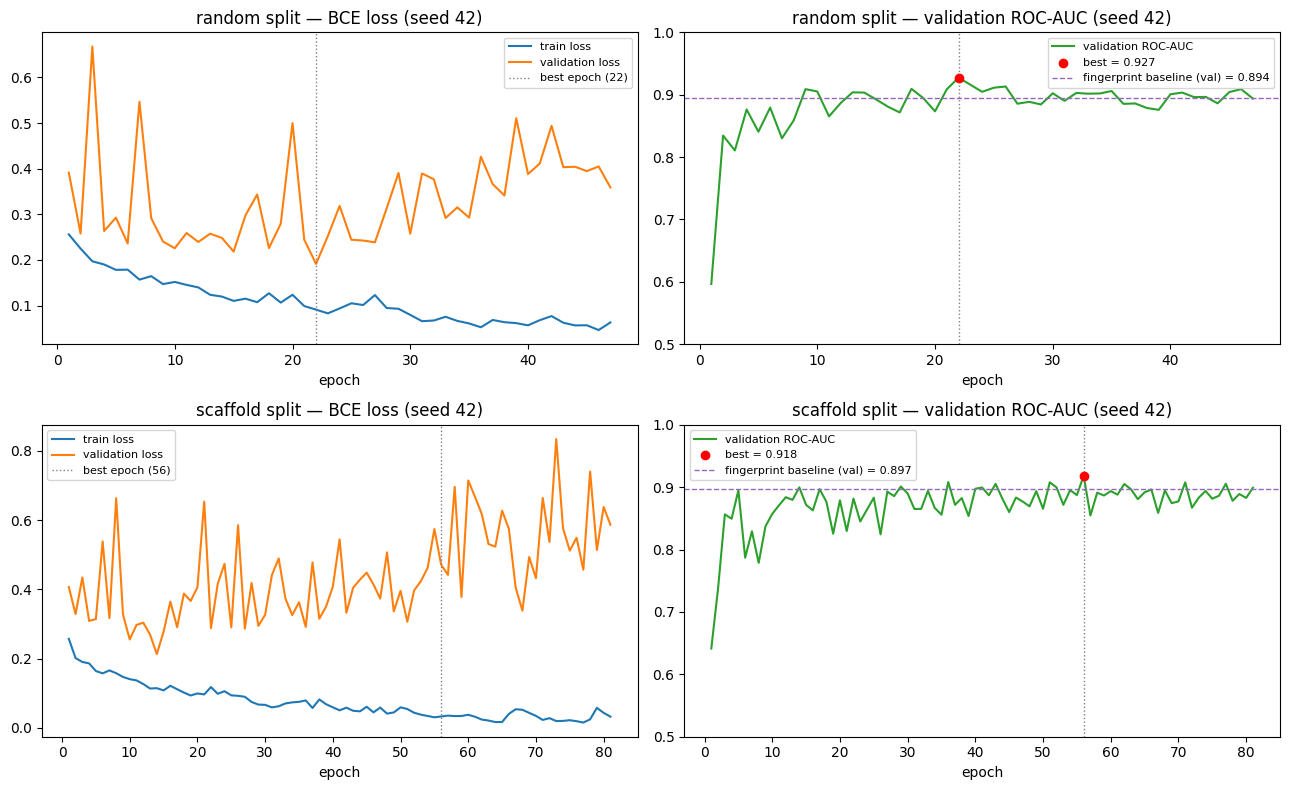

random   : stopped after  47 epochs (best epoch  22); best val ROC-AUC = 0.9272; final train loss 0.0630 vs best-epoch val loss 0.1914
scaffold : stopped after  81 epochs (best epoch  56); best val ROC-AUC = 0.9184; final train loss 0.0325 vs best-epoch val loss 0.4712


In [28]:
gnn_runs = {}                                  # (strategy, seed) -> run dictionary
for strategy in ("random", "scaffold"):
    gnn_runs[(strategy, 42)] = run_gnn(strategy, 42)

base_val_auc = {"random": 0.8940, "scaffold": 0.8966}      # frozen Part D baselines (validation)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, strategy in enumerate(("random", "scaffold")):
    run = gnn_runs[(strategy, 42)]; h = run["history"]
    ep  = np.arange(1, len(h["train_loss"]) + 1)
    ax = axes[r, 0]
    ax.plot(ep, h["train_loss"], label="train loss")
    ax.plot(ep, h["val_loss"],   label="validation loss")
    ax.axvline(run["best_epoch"], color="grey", ls=":", lw=1, label=f"best epoch ({run['best_epoch']})")
    ax.set(title=f"{strategy} split — BCE loss (seed 42)", xlabel="epoch"); ax.legend(fontsize=8)
    ax = axes[r, 1]
    ax.plot(ep, h["val_auc"], color="tab:green", label="validation ROC-AUC")
    ax.scatter([run["best_epoch"]], [run["best_val_auc"]], color="red", zorder=3,
               label=f"best = {run['best_val_auc']:.3f}")
    ax.axvline(run["best_epoch"], color="grey", ls=":", lw=1)
    ax.axhline(base_val_auc[strategy], color="tab:purple", ls="--", lw=1,
               label=f"fingerprint baseline (val) = {base_val_auc[strategy]:.3f}")
    ax.set(title=f"{strategy} split — validation ROC-AUC (seed 42)", xlabel="epoch", ylim=(0.5, 1.0))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for strategy in ("random", "scaffold"):
    run = gnn_runs[(strategy, 42)]; h = run["history"]
    print(f"{strategy:9s}: stopped after {run['epochs_run']:3d} epochs (best epoch {run['best_epoch']:3d}); "
          f"best val ROC-AUC = {run['best_val_auc']:.4f}; final train loss {h['train_loss'][-1]:.4f} vs "
          f"best-epoch val loss {h['val_loss'][run['best_epoch']-1]:.4f}")

**Reading the curves (validation data only).**

* **Overfitting, not underfitting, is the failure mode.** In both runs the training loss falls to near zero
  (0.063 random, 0.033 scaffold at stopping) while the validation loss bottoms out far higher (0.19 and 0.47 at
  the best epochs) and then rises — the network memorises the ≈1.4 k training molecules long before the epoch
  budget ends. Capacity is more than sufficient (no underfitting: training loss → 0).
* **Early stopping does its job.** The best validation ROC-AUC occurs at epoch 22 (random) and 56 (scaffold),
  and training runs 25 further epochs without improvement before stopping (47 and 81) — the checkpoint rule keeps
  the best-epoch weights rather than the last ones, which matters precisely because validation degrades after the
  optimum.
* **Mild instability.** The validation AUC oscillates epoch-to-epoch (visible in the right column), typical for
  BatchNorm on small graph batches; the best-epoch checkpoint absorbs this by selecting the peak.
* **GNN vs baseline on validation:** the seed-42 GNN beats the frozen fingerprint baseline's validation ROC-AUC
  on both strategies (0.927 vs 0.894 random; 0.918 vs 0.897 scaffold). Whether that survives the untouched test
  sets is a Part F question.

## E.4 Three seeds per split strategy

The seed-42 runs from E.3 are reused; seeds 7 and 2023 retrain the same architecture on the **same fixed splits**.
Mean ± standard deviation of validation ROC-AUC separates **seed variation** (identical split, different
initialisation/batch order) from the **split effect** (identical seeds, random vs scaffold evaluation). Test metrics
for all six runs are computed exactly once, in Part F.

In [29]:
for strategy in ("random", "scaffold"):
    for seed in (7, 2023):
        gnn_runs[(strategy, seed)] = run_gnn(strategy, seed)
        print(f"trained {strategy:9s} seed {seed:4d}: best val ROC-AUC = "
              f"{gnn_runs[(strategy, seed)]['best_val_auc']:.4f}")

rows = []
for strategy in ("random", "scaffold"):
    for seed in (42, 7, 2023):
        r = gnn_runs[(strategy, seed)]
        rows.append({"strategy": strategy, "seed": seed, "epochs run": r["epochs_run"],
                     "best epoch": r["best_epoch"], "val ROC-AUC": round(r["best_val_auc"], 4)})
    aucs = [gnn_runs[(strategy, s)]["best_val_auc"] for s in (42, 7, 2023)]
    rows.append({"strategy": strategy, "seed": "mean ± std", "epochs run": "", "best epoch": "",
                 "val ROC-AUC": f"{np.mean(aucs):.4f} ± {np.std(aucs):.4f}"})
gnn_val_table = pd.DataFrame(rows)
display(gnn_val_table)

trained random    seed    7: best val ROC-AUC = 0.9256


trained random    seed 2023: best val ROC-AUC = 0.9357


trained scaffold  seed    7: best val ROC-AUC = 0.9229


trained scaffold  seed 2023: best val ROC-AUC = 0.9262


,strategy,seed,epochs run,best epoch,val ROC-AUC
0,random,42,47,22,0.9272
1,random,7,51,26,0.9256
2,random,2023,87,62,0.9357
3,random,mean ± std,,,0.9295 ± 0.0044
4,scaffold,42,81,56,0.9184
5,scaffold,7,53,28,0.9229
6,scaffold,2023,80,55,0.9262
7,scaffold,mean ± std,,,0.9225 ± 0.0032


**Seed variation vs split effect.** Validation ROC-AUC is 0.9295 ± 0.0044 (random) versus 0.9225 ± 0.0032
(scaffold). Two honest observations:

1. **Seed noise is real but small** (std ≤ 0.0044): every individual run lands between 0.918 and 0.936, and the
   training length itself is seed-dependent (best epochs 22–62), so single-seed numbers would be unreliable to
   quote to three decimals.
2. **The split gap on validation (0.9295 − 0.9225 = 0.0070) is only ≈1.5–2 seed standard deviations** — larger
   than any within-strategy spread, but not by much. So on *validation* data the scaffold evaluation is slightly
   harder, yet the difference is of the same order as seed variation; the decisive, untouched-test-set comparison
   (including the class-drifted scaffold test subset, C.4) is deferred to Part F, where mean ± std over these same
   three seeds is reported.

All six runs also stay above the fingerprint baseline's validation ROC-AUC (≥ 0.918 vs ≈ 0.89), so the GNN's
advantage is consistent across seeds on both splits — on validation data.